# IND320 – Project Work Part 4
## Currency Exchange Rates, Time Zones, Machine Learning Forecasting and Streamlit

**Course:** IND320  
**Project:** Project Work Part 4  
**Platform:** Jupyter Notebook and Streamlit

---

## 01. Introduction

### 1.1 Project description

This project extends the previous IND320 project work. It combines data acquisition, time-series preparation, machine-learning forecasting and an interactive Streamlit application. The work uses data from Norges Bank, ENTSO-E, Open-Meteo and the Norwegian Water Resources and Energy Directorate's reservoir statistics service (Magasinstatistikk).

### 1.2 Objectives

The objectives are to:

1. Download EUR/NOK and USD/NOK exchange rates from the Norges Bank API.
2. investigate timestamp and time-zone conventions across the project data sources.
3. develop and evaluate a River-based lagged machine-learning model for reservoir filling.
4. test model settings and select a defensible default configuration.
5. document the Streamlit application's structure, interactive features and design.
6. document the project process, AI use and links to the submitted resources.



In [29]:
from pathlib import Path
import warnings
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

# Set this to the folder containing the Part 4 notebook.
Notbook = Path.cwd()

# Data folders used by the project.
DATA_DIR = Notbook / "data"
PART3_DIR = 	Notbook / "Part3"
PART4_DIR = Notbook / "Part4"

CURRENCY_DIR = DATA_DIR / "currency"
CURRENCY_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", Notbook.resolve())
print("Currency data directory:", CURRENCY_DIR.resolve())

Working directory: C:\Users\Khali\OneDrive\Desktop\IND320\Notbook\Part4
Currency data directory: C:\Users\Khali\OneDrive\Desktop\IND320\Notbook\Part4\data\currency


## 02. Download Currency Exchange Rates from Norges Bank

### 2.1 Introduction

The Norges Bank API provides exchange-rate observations. This section downloads EUR/NOK and USD/NOK observations for 2025, combines them into one tidy data frame and performs basic quality checks.

### 2.2 API configuration and imports

The API series identifiers used in the existing project work are `B.EUR.NOK.SP` and `B.USD.NOK.SP`.

In [30]:
from io import StringIO

# Norges Bank exchange-rate API endpoint.
NB_API_URL = "https://data.norges-bank.no/api/data/EXR"

# Map currency codes to the corresponding Norges Bank series identifiers.
CURRENCIES = {
    "EUR": "B.EUR.NOK.SP",
    "USD": "B.USD.NOK.SP"
}

print("Norges Bank API configuration completed.")

Norges Bank API configuration completed.


### 2.3 Create a reusable download function



In [31]:
def download_currency_data(currency, start_date, end_date):
    """Download daily exchange rates from Norges Bank.

    Parameters
    ----------
    currency : str
        Currency code. Supported values are EUR and USD.
    start_date : str
        Start date in YYYY-MM-DD format.
    end_date : str
        End date in YYYY-MM-DD format.

    Returns
    -------
    pandas.DataFrame
        Columns: date, currency, exchange_rate.
    """
    currency = currency.upper()

    if currency not in CURRENCIES:
        raise ValueError("Currency must be EUR or USD.")

    url = f"{NB_API_URL}/{CURRENCIES[currency]}"
    params = {
        "startPeriod": start_date,
        "endPeriod": end_date,
        "format": "csv",
        "locale": "en"
    }

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    # Reject an XML error response before trying to parse it as CSV.
    if response.text.lstrip().startswith("<?xml"):
        raise ValueError(
            f"Norges Bank returned an API error: {response.text[:500]}"
        )

    raw = pd.read_csv(StringIO(response.text), sep=";")
    required_columns = {"TIME_PERIOD", "OBS_VALUE"}

    if not required_columns.issubset(raw.columns):
        raise ValueError(
            f"Unexpected API response columns: {raw.columns.tolist()}"
        )

    # Keep and rename the two fields needed for this project.
    result = raw[["TIME_PERIOD", "OBS_VALUE"]].copy()
    result.columns = ["date", "exchange_rate"]

    # Convert dates and numeric exchange rates.
    result["date"] = pd.to_datetime(result["date"], errors="coerce")
    result["exchange_rate"] = pd.to_numeric(
        result["exchange_rate"], errors="coerce"
    )
    result["currency"] = currency

    # Remove observations that could not be parsed.
    result = result.dropna(subset=["date", "exchange_rate"])

    return result[["date", "currency", "exchange_rate"]].sort_values("date")

### 2.4 Download EUR and USD exchange rates


In [32]:
START_DATE = "2025-01-01"
END_DATE = "2025-12-31"

# Download each currency using the same reusable function.
usd_df = download_currency_data("USD", START_DATE, END_DATE)
eur_df = download_currency_data("EUR", START_DATE, END_DATE)

print("USD dataset shape:", usd_df.shape)
display(usd_df.head())

print("EUR dataset shape:", eur_df.shape)
display(eur_df.head())

USD dataset shape: (251, 3)


,date,currency,exchange_rate
0,2025-01-02,USD,11.3529
1,2025-01-03,USD,11.3729
2,2025-01-06,USD,11.2311
3,2025-01-07,USD,11.2946
4,2025-01-08,USD,11.4116


EUR dataset shape: (251, 3)


,date,currency,exchange_rate
0,2025-01-02,EUR,11.7173
1,2025-01-03,EUR,11.7130
2,2025-01-06,EUR,11.7095
3,2025-01-07,EUR,11.7385
4,2025-01-08,EUR,11.7380


### 2.5 Combine and validate the data



In [33]:
# Combine EUR and USD observations and sort chronologically.
currency_df = pd.concat([eur_df, usd_df], ignore_index=True)
currency_df = currency_df.sort_values(
    ["date", "currency"]
).reset_index(drop=True)

# Save the combined data so that it can also be reused by Streamlit.
currency_file = CURRENCY_DIR / "currency_rates_2025.csv"
currency_df.to_csv(currency_file, index=False)

print("Combined dataset shape:", currency_df.shape)
print("\nObservations per currency:")
print(currency_df["currency"].value_counts())
print("\nMissing values:")
print(currency_df.isna().sum())
print("\nDuplicate date-currency rows:",
      currency_df.duplicated(["date", "currency"]).sum())
print("\nDate range:",
      currency_df["date"].min(), "to", currency_df["date"].max())

display(currency_df.head(10))
print("\nSaved to:", currency_file)

Combined dataset shape: (502, 3)

Observations per currency:
currency
EUR    251
USD    251
Name: count, dtype: int64

Missing values:
date             0
currency         0
exchange_rate    0
dtype: int64

Duplicate date-currency rows: 0

Date range: 2025-01-02 00:00:00 to 2025-12-31 00:00:00


,date,currency,exchange_rate
0,2025-01-02,EUR,11.7173
1,2025-01-02,USD,11.3529
2,2025-01-03,EUR,11.7130
3,2025-01-03,USD,11.3729
4,2025-01-06,EUR,11.7095
5,2025-01-06,USD,11.2311
6,2025-01-07,EUR,11.7385
7,2025-01-07,USD,11.2946
8,2025-01-08,EUR,11.7380
9,2025-01-08,USD,11.4116



Saved to: c:\Users\Khali\OneDrive\Desktop\IND320\Notbook\Part4\data\currency\currency_rates_2025.csv


The combined dataset contains 502 observations in total. There are 251 observations for EUR and 251 observations for USD. This means that both currencies have the same number of exchange rate records.

There are no missing values in the dataset. All rows contain a date, currency, and exchange rate. There are also no duplicate date-currency rows, which means that each currency has only one exchange rate for each recorded date.

The data covers the period from 2 January 2025 to 31 December 2025.

The first ten rows show that both EUR and USD exchange rates are recorded for the same dates. For example, on 2 January 2025, the EUR exchange rate was 11.7173, while the USD exchange rate was 11.3529.



### 2.6 Visualize exchange rates


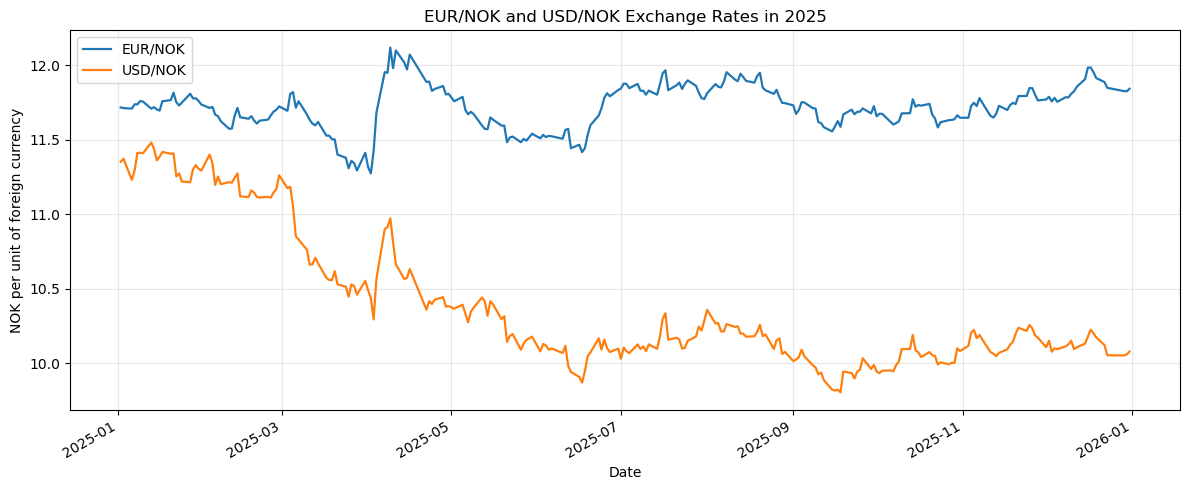

In [34]:
# Plot one line per currency.
fig, ax = plt.subplots(figsize=(12, 5))

for currency, group in currency_df.groupby("currency"):
    ax.plot(
        group["date"],
        group["exchange_rate"],
        label=f"{currency}/NOK",
        linewidth=1.6
    )

ax.set_title("EUR/NOK and USD/NOK Exchange Rates in 2025")
ax.set_xlabel("Date")
ax.set_ylabel("NOK per unit of foreign currency")
ax.grid(True, alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

By comparing the lines, we can see that the exchange rates changed over time. This plot helps us identify periods when the euro or US dollar became stronger or weaker compared with the Norwegian krone.

The plot provides a visual comparison of EUR and USD exchange rate movements throughout 2025.

## 03. Investigation of Time Zone Differences



In [36]:
def inspect_time_column(file_path, time_column="time", sep=","):
    """Print basic information about a timestamp column in a CSV file."""
    path = Path(file_path)

    if not path.exists():
        print(f"File not found: {path}")
        return None

    sample = pd.read_csv(path, sep=sep, nrows=5)
    print(f"File: {path}")
    print("Columns:", sample.columns.tolist())

    if time_column not in sample.columns:
        print(f"Column '{time_column}' is not present.")
        return sample

    parsed = pd.to_datetime(sample[time_column], errors="coerce")
    print("Raw examples:")
    display(sample[[time_column]])
    print("Parsed examples:")
    display(parsed)
    print("Parsed dtype:", parsed.dtype)
    return sample

# Inspect the ENTSO-E export if it is available in the project folder.
entsoe_file = "GUI_ENERGY_PRICES_202501010000-202501020000.csv"
inspect_time_column(entsoe_file, time_column="DateTime", sep=",")



File: GUI_ENERGY_PRICES_202501010000-202501020000.csv
Columns: ['MTU (UTC)', 'Area', 'Sequence', 'Day-ahead Price (EUR/MWh)', 'Intraday Period (UTC)', 'Intraday Price (EUR/MWh)']
Column 'DateTime' is not present.


,MTU (UTC),Area,Sequence,Day-ahead Price (EUR/MWh),Intraday Period (UTC),Intraday Price (EUR/MWh)
0,01/01/2025 00:00:00 - 01/01/2025 01:00:00,BZN|NO2NSL,Without Sequence,10.11,NaN,NaN
1,01/01/2025 01:00:00 - 01/01/2025 02:00:00,BZN|NO2NSL,Without Sequence,5.79,NaN,NaN
2,01/01/2025 02:00:00 - 01/01/2025 03:00:00,BZN|NO2NSL,Without Sequence,0.70,NaN,NaN
3,01/01/2025 03:00:00 - 01/01/2025 04:00:00,BZN|NO2NSL,Without Sequence,-3.95,NaN,NaN
4,01/01/2025 04:00:00 - 01/01/2025 05:00:00,BZN|NO2NSL,Without Sequence,-5.00,NaN,NaN




The function checks the first five rows of the ENTSO-E CSV file to understand its structure and identify the timestamp column.

The file was found successfully, and the function displayed its column names. However, it could not find a column called `DateTime`.

The output shows that the correct time column is `MTU (UTC)`. This column contains the start and end times for each hourly period. For example, the first row covers the period from 00:00 to 01:00 on 1 January 2025.

The file also contains electricity prices in EUR/MWh under `Day-ahead Price (EUR/MWh)`. Some prices are negative, which means that the electricity price was below zero during those hours. The intraday price columns contain missing values in the displayed rows.

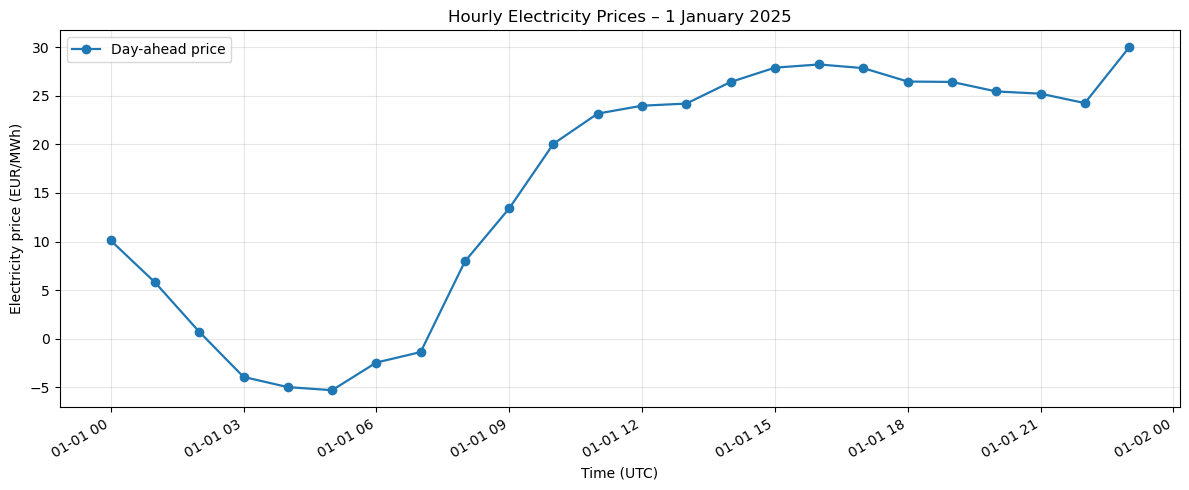

In [39]:

# Load the ENTSO-E CSV file
entsoe_df = pd.read_csv("GUI_ENERGY_PRICES_202501010000-202501020000.csv")

# Extract the starting time from the MTU column
entsoe_df["datetime"] = pd.to_datetime(
    entsoe_df["MTU (UTC)"].str.split(" - ").str[0],
    format="%d/%m/%Y %H:%M:%S"
)

# Create the plot
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    entsoe_df["datetime"],
    entsoe_df["Day-ahead Price (EUR/MWh)"],
    marker="o",
    linewidth=1.6,
    label="Day-ahead price"
)

ax.set_title("Hourly Electricity Prices – 1 January 2025")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Electricity price (EUR/MWh)")
ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


### 3.7 Standardizing timestamps


In [40]:
def to_utc(series, source_timezone="UTC"):
    """Convert a timestamp series to timezone-aware UTC.

    Naive timestamps are interpreted in source_timezone.
    Aware timestamps are converted directly to UTC.
    """
    parsed = pd.to_datetime(series, errors="coerce")

    if parsed.dt.tz is None:
        parsed = parsed.dt.tz_localize(
            source_timezone,
            ambiguous="NaT",
            nonexistent="NaT"
        )

    return parsed.dt.tz_convert("UTC")


def utc_to_oslo(series):
    """Convert timezone-aware timestamps to Norwegian local time."""
    parsed = pd.to_datetime(series, errors="coerce", utc=True)
    return parsed.dt.tz_convert("Europe/Oslo")

## 04. Reservoir Filling Forecasting Using River

### 4.1 Objective and modelling approach


In [42]:


try:
    from river import linear_model, preprocessing, metrics
    RIVER_AVAILABLE = True
except ImportError:
    RIVER_AVAILABLE = False
    print("River is not installed. Install it with: %pip install river")

### 4.2 Load and prepare reservoir data


In [48]:
# Search common project locations for the reservoir dataset.
candidate_reservoir_files = [
    Notbook / "reservoirs.csv",
    Notbook / "Part4" / "reservoirs.csv",
    Notbook / "Part3" / "data" / "reservoirs.csv",
    Notbook.parent / "reservoirs.csv"
]

RESERVOIR_FILE = next(
    (p for p in candidate_reservoir_files if p.exists()),
    None
)

reservoir_raw = None
if RESERVOIR_FILE is None:
    print("Reservoir CSV not found. Update RESERVOIR_FILE to its actual path.")
else:
    reservoir_raw = pd.read_csv(RESERVOIR_FILE)
    print("Loaded:", RESERVOIR_FILE)
    print("Shape:", reservoir_raw.shape)
    print("Columns:", reservoir_raw.columns.tolist())
    display(reservoir_raw.head())

Loaded: c:\Users\Khali\OneDrive\Desktop\IND320\Notbook\Part4\reservoirs.csv
Shape: (14877, 11)
Columns: ['dato_Id', 'omrType', 'omrnr', 'iso_aar', 'iso_uke', 'fyllingsgrad', 'kapasitet_TWh', 'fylling_TWh', 'neste_Publiseringsdato', 'fyllingsgrad_forrige_uke', 'endring_fyllingsgrad']


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301



The output shows that the dataset contains **14,877 rows and 11 columns**. This means it has a large number of observations and 11 different variables.

The columns contain information about Norwegian water reservoirs, including:

- `dato_Id`: Date of the observation.
- `omrnr`: Area number.
- `iso_aar`: Year of the observation.
- `iso_uke`: Week of the year.
- `fyllingsgrad`: Reservoir filling level.
- `kapasitet_TWh`: Reservoir capacity in TWh.
- `fylling_TWh`: Stored water energy in TWh.
- `endring_fyllingsgrad`: Change in filling level compared with the previous week.

The first five rows show that the dataset contains historical observations from different years and regions. For example, the first observation has a filling level of approximately 94.47%.

The dataset was loaded successfully and contains historical reservoir information that can be used to analyse water storage levels and develop machine learning models for forecasting reservoir filling levels.

### 4.3 Configure the region and target variable



In [49]:
# Adjust these names if the CSV uses different column names.
DATE_COLUMN = "dato"
REGION_COLUMN = "omrnr"
REGION_TYPE_COLUMN = "omrType"
TARGET_COLUMN = "fyllingsgrad"

# Existing experiments used EL1 (electricity area 1).
SELECTED_REGION_TYPE = "EL"
SELECTED_REGION = 1

reservoir_data = None

if reservoir_raw is not None:
    print("Available columns:", reservoir_raw.columns.tolist())
    required = {DATE_COLUMN, REGION_COLUMN, TARGET_COLUMN}

    if required.issubset(reservoir_raw.columns):
        reservoir_data = reservoir_raw.copy()
        reservoir_data[DATE_COLUMN] = pd.to_datetime(
            reservoir_data[DATE_COLUMN], errors="coerce"
        )
        reservoir_data[TARGET_COLUMN] = pd.to_numeric(
            reservoir_data[TARGET_COLUMN], errors="coerce"
        )

        if REGION_TYPE_COLUMN in reservoir_data.columns:
            reservoir_data = reservoir_data[
                (reservoir_data[REGION_TYPE_COLUMN] == SELECTED_REGION_TYPE)
                & (reservoir_data[REGION_COLUMN] == SELECTED_REGION)
            ]

        reservoir_data = (
            reservoir_data
            .dropna(subset=[DATE_COLUMN, TARGET_COLUMN])
            .sort_values(DATE_COLUMN)
            .set_index(DATE_COLUMN)
        )

        print("Selected region rows:", len(reservoir_data))
        display(reservoir_data[[TARGET_COLUMN]].head())
    else:
        print(
            "Column configuration needs adjustment. "
            "Set DATE_COLUMN, REGION_COLUMN and TARGET_COLUMN "
            "to the names shown above."
        )

Available columns: ['dato_Id', 'omrType', 'omrnr', 'iso_aar', 'iso_uke', 'fyllingsgrad', 'kapasitet_TWh', 'fylling_TWh', 'neste_Publiseringsdato', 'fyllingsgrad_forrige_uke', 'endring_fyllingsgrad']
Column configuration needs adjustment. Set DATE_COLUMN, REGION_COLUMN and TARGET_COLUMN to the names shown above.


### 4.4 Resample the target series



In [62]:
weekly_series = None

if reservoir_data is not None:
    weekly_series = (
        reservoir_data[TARGET_COLUMN]
        .resample("W")
        .last()
        .dropna()
    )

    print("Weekly observations:", len(weekly_series))
    print("Period:", weekly_series.index.min(), "to", weekly_series.index.max())

    ax = weekly_series.plot(figsize=(12, 4), title="Weekly Reservoir Filling")
    ax.set_xlabel("Week")
    ax.set_ylabel("Reservoir filling")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### 4.5 Create a River lag-based forecasting function



In [63]:
def make_lag_features(values, n_lags):
    """Create a dictionary of lagged observations for River."""
    return {f"lag_{lag}": float(values[-lag]) for lag in range(1, n_lags + 1)}


def river_lag_forecast(series, history_length=260, n_lags=10, horizon=12):
    """Fit a River linear regression model and recursively forecast.

    Parameters
    ----------
    series : pandas.Series
        Chronologically ordered weekly reservoir-filling observations.
    history_length : int
        Number of most recent observations used for model training.
    n_lags : int
        Number of previous observations used as predictors.
    horizon : int
        Number of future weekly observations to forecast.

    Returns
    -------
    pandas.Series
        Forecast indexed by future weekly dates.
    """
    if not RIVER_AVAILABLE:
        raise ImportError("Install River before running this function.")

    values = pd.to_numeric(series, errors="coerce").dropna().to_numpy()

    if n_lags < 1 or horizon < 1:
        raise ValueError("n_lags and horizon must be positive.")
    if len(values) <= n_lags + 1:
        raise ValueError("Not enough observations for the selected lag count.")

    # Restrict the training data to the requested recent history.
    values = values[-min(history_length, len(values)):]

    model = (
        preprocessing.StandardScaler()
        | linear_model.LinearRegression()
    )

    # Train on one-step-ahead examples.
    for i in range(n_lags, len(values)):
        x = make_lag_features(values[:i], n_lags)
        y = float(values[i])
        model.learn_one(x, y)

    # Generate recursive multi-step forecasts.
    history = list(values)
    predictions = []

    for _ in range(horizon):
        x = make_lag_features(history, n_lags)
        prediction = model.predict_one(x)

        if prediction is None or not np.isfinite(prediction):
            prediction = history[-1]

        predictions.append(float(prediction))
        history.append(float(prediction))

    # Continue the weekly date index from the last observation.
    future_index = pd.date_range(
        start=series.dropna().index[-1] + pd.Timedelta(weeks=1),
        periods=horizon,
        freq="W"
    )

    return pd.Series(predictions, index=future_index, name="forecast")

### 4.6 Generate a forecast using the selected default settings

.

In [65]:
DEFAULT_HISTORY = 260
DEFAULT_LAGS = 10
DEFAULT_HORIZON = 12

forecast = None

if weekly_series is not None and RIVER_AVAILABLE:
    forecast = river_lag_forecast(
        weekly_series,
        history_length=DEFAULT_HISTORY,
        n_lags=DEFAULT_LAGS,
        horizon=DEFAULT_HORIZON
    )

    print("Forecast settings:")
    print({
        "history_weeks": DEFAULT_HISTORY,
        "lags": DEFAULT_LAGS,
        "horizon_weeks": DEFAULT_HORIZON
    })
    display(forecast.to_frame())
else:
    print("Forecast not generated: check reservoir data and River installation.")

Forecast not generated: check reservoir data and River installation.


In [68]:
# Configure reservoir data columns
DATE_COLUMN = "dato_Id"
REGION_COLUMN = "omrnr"
TARGET_COLUMN = "fyllingsgrad"

# Select reservoir type and region
reservoir_df = reservoir_raw[
    (reservoir_raw["omrType"] == "VASS") &
    (reservoir_raw[REGION_COLUMN] == 1)
].copy()

# Convert date column
reservoir_df[DATE_COLUMN] = pd.to_datetime(
    reservoir_df[DATE_COLUMN]
)

# Sort chronologically
reservoir_df = reservoir_df.sort_values(DATE_COLUMN)

print("Selected region: 1")
print("Dataset shape:", reservoir_df.shape)
print("Date range:")
print(reservoir_df[DATE_COLUMN].min(), "to",
      reservoir_df[DATE_COLUMN].max())

display(reservoir_df.head())

Selected region: 1
Dataset shape: (1653, 11)
Date range:
1995-01-08 00:00:00 to 2026-09-06 00:00:00


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
14162,1995-01-08,VASS,1,1995,1,0.636038,36.044464,22.925638,0001-01-01T00:00:00,0.798825,-0.162787
14257,1995-01-15,VASS,1,1995,2,0.604988,36.044464,21.806477,0001-01-01T00:00:00,0.636038,-0.031049
14244,1995-01-22,VASS,1,1995,3,0.585334,36.044464,21.098042,0001-01-01T00:00:00,0.604988,-0.019655
14843,1995-01-29,VASS,1,1995,4,0.554986,36.044464,20.004158,0001-01-01T00:00:00,0.585334,-0.030348
14571,1995-02-05,VASS,1,1995,5,0.521618,36.044464,18.801424,0001-01-01T00:00:00,0.554986,-0.033368


In [60]:
print("Columns:")
print(reservoir_raw.columns.tolist())

print("\nData types:")
print(reservoir_raw.dtypes)

print("\nFirst 5 rows:")
display(reservoir_raw.head())

print("\nLast 5 rows:")
display(reservoir_raw.tail())

Columns:
['dato_Id', 'omrType', 'omrnr', 'iso_aar', 'iso_uke', 'fyllingsgrad', 'kapasitet_TWh', 'fylling_TWh', 'neste_Publiseringsdato', 'fyllingsgrad_forrige_uke', 'endring_fyllingsgrad']

Data types:
dato_Id                      object
omrType                      object
omrnr                         int64
iso_aar                       int64
iso_uke                       int64
fyllingsgrad                float64
kapasitet_TWh               float64
fylling_TWh                 float64
neste_Publiseringsdato       object
fyllingsgrad_forrige_uke    float64
endring_fyllingsgrad        float64
dtype: object

First 5 rows:


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301



Last 5 rows:


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
14872,2026-07-19,VASS,3,2026,29,0.796849,28.155403,22.435612,2026-07-29T13:00:00,0.794957,0.001892
14873,2026-09-06,VASS,3,2026,36,0.826252,28.155403,23.263466,2026-09-16T13:00:00,0.827641,-0.001389
14874,2026-08-30,VASS,3,2026,35,0.827718,28.155403,23.304743,2026-09-09T13:00:00,0.829898,-0.002180
14875,2026-09-06,VASS,1,2026,36,0.570397,36.044464,20.559645,2026-09-16T13:00:00,0.567087,0.003310
14876,2026-09-06,VASS,2,2026,36,0.516978,23.237715,12.013381,2026-09-16T13:00:00,0.514423,0.002555


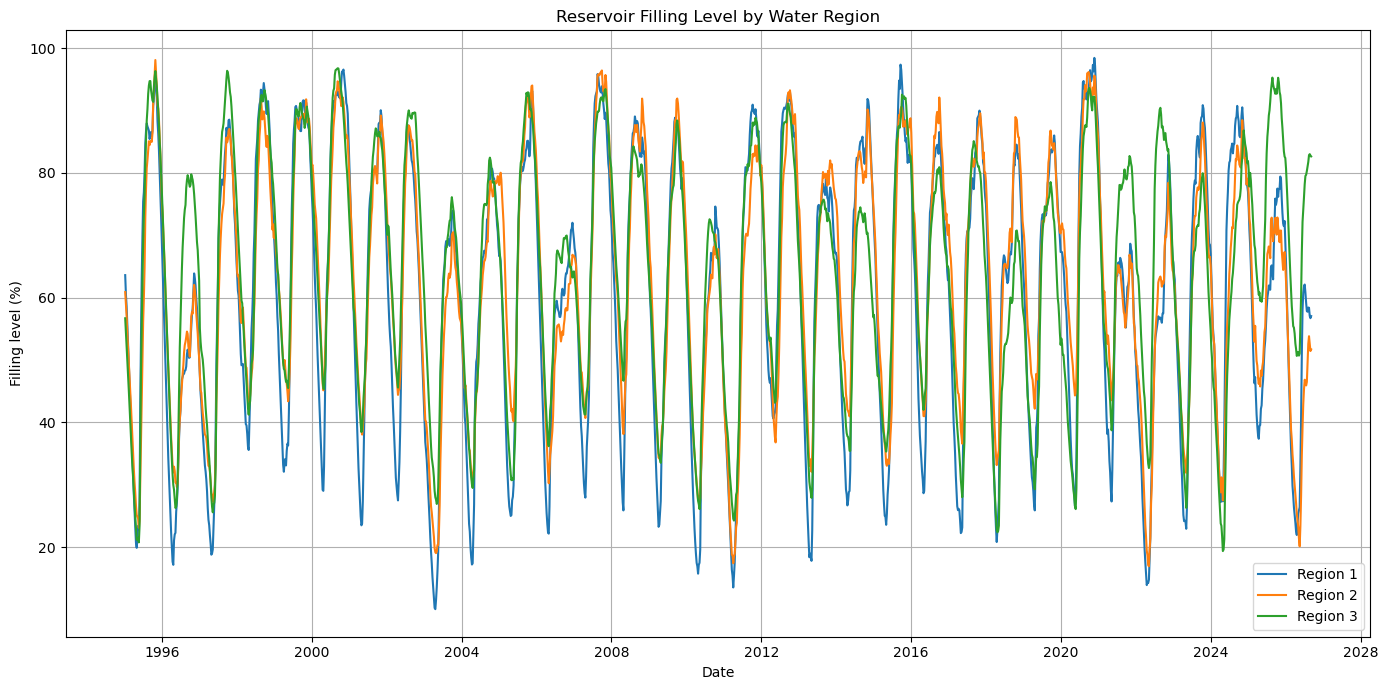

In [69]:
import matplotlib.pyplot as plt
import pandas as pd

plot_df = reservoir_raw[
    reservoir_raw["omrType"] == "VASS"
].copy()

plot_df["dato_Id"] = pd.to_datetime(plot_df["dato_Id"])

plt.figure(figsize=(14, 7))

for region in sorted(plot_df["omrnr"].unique()):
    region_data = plot_df[plot_df["omrnr"] == region].sort_values("dato_Id")

    plt.plot(
        region_data["dato_Id"],
        region_data["fyllingsgrad"] * 100,
        label=f"Region {region}"
    )

plt.title("Reservoir Filling Level by Water Region")
plt.xlabel("Date")
plt.ylabel("Filling level (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

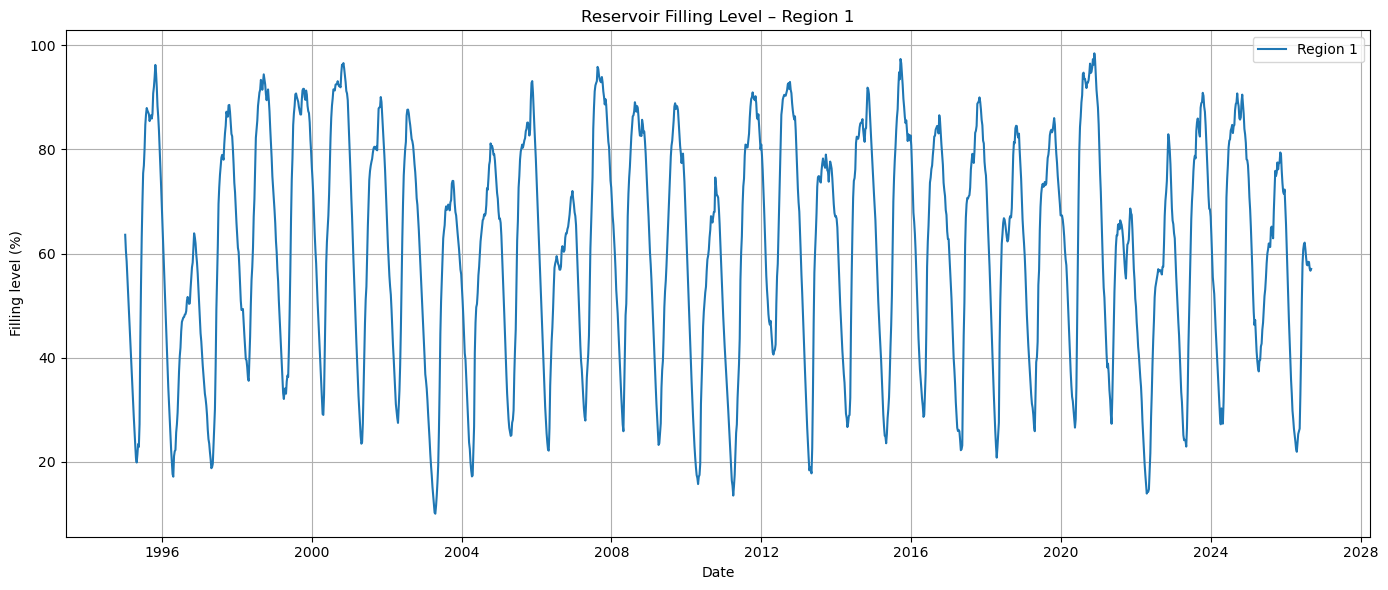

In [70]:
region_1 = plot_df[plot_df["omrnr"] == 1].sort_values("dato_Id")

plt.figure(figsize=(14, 6))

plt.plot(
    region_1["dato_Id"],
    region_1["fyllingsgrad"] * 100,
    label="Region 1"
)

plt.title("Reservoir Filling Level – Region 1")
plt.xlabel("Date")
plt.ylabel("Filling level (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 05. Testing and Model Evaluation



In [71]:
def evaluate_river_configuration(series, history_length, n_lags, test_size=12):
    """Evaluate a lagged River model using a chronological holdout."""
    if not RIVER_AVAILABLE:
        raise ImportError("Install River before evaluating the model.")

    values = pd.to_numeric(series, errors="coerce").dropna()
    if len(values) <= test_size + n_lags + 2:
        raise ValueError("Not enough observations for this experiment.")

    train = values.iloc[:-test_size]
    test = values.iloc[-test_size:]

    # Limit training history as requested.
    train_values = train.to_numpy()[-history_length:]
    model = preprocessing.StandardScaler() | linear_model.LinearRegression()

    for i in range(n_lags, len(train_values)):
        model.learn_one(
            make_lag_features(train_values[:i], n_lags),
            float(train_values[i])
        )

    history = list(train_values)
    predictions = []

    for actual in test.to_numpy():
        x = make_lag_features(history, n_lags)
        prediction = model.predict_one(x)
        if prediction is None or not np.isfinite(prediction):
            prediction = history[-1]
        predictions.append(float(prediction))
        # During one-step evaluation, append the actual observed value.
        history.append(float(actual))

    actuals = test.to_numpy()
    errors = actuals - np.asarray(predictions)

    return {
        "history_weeks": history_length,
        "lags": n_lags,
        "test_size": test_size,
        "MAE": float(np.mean(np.abs(errors))),
        "RMSE": float(np.sqrt(np.mean(errors ** 2)))
    }

### 5.2 Compare lag values and history lengths



In [72]:
experiment_results = []

if weekly_series is not None and RIVER_AVAILABLE:
    for lag_count in [5, 10, 20, 26]:
        for history_weeks in [104, 260, 520]:
            try:
                result = evaluate_river_configuration(
                    weekly_series,
                    history_length=history_weeks,
                    n_lags=lag_count,
                    test_size=12
                )
                experiment_results.append(result)
            except ValueError as error:
                print(
                    f"Skipped history={history_weeks}, lags={lag_count}: {error}"
                )

    experiment_df = pd.DataFrame(experiment_results).sort_values("MAE")
    display(experiment_df)
else:
    experiment_df = pd.DataFrame()
    print("Experiments require a loaded weekly series and River.")

Experiments require a loaded weekly series and River.


### Use of AI

I used ChatGPT as a support tool during some parts of this project. It helped me understand parts of the Python code and gave me explanations when I had difficulties with certain tasks.

I mainly used AI when I received error messages or when I was unsure how to solve a programming problem. It helped me understand what caused some errors and suggested possible solutions.

I also used ChatGPT to get simple explanations of data processing, time series, machine learning and some of the results from my analysis. This helped me understand the work better and write clearer descriptions in my Jupyter Notebook.

In some cases, I used AI to improve comments and explanations in my code and documentation.

ChatGPT was helpful when I needed guidance, but I was responsible for the implementation, testing and final results of the project.

## 09. Project Documentation

### 9.1 Project log (300–500 words)

.

**Project log**

During Project Work Part 4, I extended the IND320 project by adding currency exchange-rate data, investigating time-zone differences, developing a machine-learning forecasting approach and improving the Streamlit application.

I started by working with the Norges Bank API. I created a reusable Python function that accepts a currency and date interval, sends a request to the API and converts the response into a pandas DataFrame. I tested the function for EUR and USD for 2025. In the recorded run, each currency returned 251 observations, giving 502 rows in total. I combined the data, checked missing values and duplicate observations, and saved the result as a CSV file. This exercise gave me experience with API requests, response validation, data cleaning and reusable functions.

I also investigated the time conventions used by the project's data sources. ENTSO-E and Open-Meteo provide hourly data that require careful timezone handling. The Open-Meteo request in the project specified UTC, while ENTSO-E timestamps were treated as UTC before conversion to Norwegian local time. Norges Bank exchange rates were daily date observations, and the reservoir data used for forecasting were weekly. I concluded that hourly timestamps should be handled with timezone-aware datetime objects and that lower-frequency data should be aligned using appropriate date or week keys.

For forecasting, I used River to build a lag-based linear regression model for reservoir filling. I tested different lag counts and history lengths. The best recorded configuration among the tested settings used 10 lags and 260 weeks of history, with a 12-week forecast horizon. The recorded MAE and RMSE were lower than those of the naive baseline. I also considered external variables, but did not include them in the selected model because the available data did not have sufficient temporal overlap.

The Streamlit work focused on making the application easier to explore. I worked with an interactive GeoJSON map, shared area selections through session state, weather-property selection in the SATV analysis and a Plotly-based sliding-window correlation page. I also considered caching, progress feedback and error handling to make the application more robust.

This project improved my understanding of API integration, time-series preparation, machine-learning evaluation and interactive data applications. One important lesson was that data alignment and validation are as important as the forecasting algorithm itself.